# rhizodep in metafspm: the root architecture and its growth

In metafspm, rhizodep's growth component is two classes:

- **`RootArchitecture`**, the root architecture without carbon (ArchiSimple): the apices' development (elongation from their
  diameter, growth durations, emergences, stops, deaths), the pipe model, segmentation and lateral primordia; its growth is
  the potential growth times the plant's satisfaction coefficient;
- **`RootGrowth(RootArchitecture)`**, the same architecture with its growth limited by resources (hexose by default): each
  elongating apex draws on the hexose of its supply zone, each thickening segment on its own, and the costs are taken from
  the elements that supply them. It reproduces the original component (`openalea.rhizodep.legacy`) bit for bit.

Both are `StructuralComponent`s: they build each plant's root system in metafspm's multiscale plant graph (MPG) and grow
it there, every root element (segment or apex) a SubOrgan.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.scene.scene import Scene
from openalea.rhizodep.architecture import RootArchitecture
from openalea.rhizodep.growth import RootGrowth
from openalea.rhizodep.comparison.parameter_sets import WHEAT_SOISSON
from openalea.rhizodep.comparison.port_run import snapshot
from openalea.rhizodep.comparison.drawing import draw_root_system, totals

## 1. A plant model, a planting table

A plant model names its **initiators** (the components that build each plant: here `RootGrowth`, which builds the
seedling) and its components. Here the hexose is given (a carbon model would compute it), so the model writes it before
each step.

In [2]:
class Roots:
    initiators = (RootGrowth,)

    def __init__(self, data_structure, time_step, C_hexose_root=1e-3):
        self.data_structure, self.C_hexose_root = data_structure, C_hexose_root
        self.growth = RootGrowth(data_structure=data_structure, time_step=time_step)
        self.components = [self.growth]

    def run(self):
        self.data_structure.set("C_hexose_root", np.full(self.data_structure.n_nodes(), self.C_hexose_root))
        self.growth()


def planting(model, scenarios):
    """One plant per scenario, side by side."""
    table = pd.DataFrame([dict(plant=f"plant {i}", model=model, x=0.2 * i, y=0., z=0., rotation=0., scenario=s)
                          for i, s in enumerate(scenarios)])
    table.attrs.update(xrange=0.2 * len(scenarios), yrange=0.2)
    return table

## 2. Parametrization by scenario

A plant's scenario sets the components' parameters over their defaults, as Wheat-BRIDGES' scenarios do (here the
`wheat_soisson` column of its scenario table). Numeric parameters are per plant: two plants of one population may differ.

In [3]:
thin = dict(WHEAT_SOISSON, D_ini=4e-4)
scene = Scene(planting(Roots, [{"parameters": WHEAT_SOISSON}, {"parameters": thin}]), time_step=3600)
scene.simulate(24 * 8)                                     # 8 days, hourly
ds = scene.populations[0].data_structure
print(f"{ds.n_nodes()} root elements in {len(ds.entity_ids('Plant'))} plants")
print("D_ini per plant:", scene.populations[0].instance.growth.D_ini)

782 root elements in 2 plants
D_ini per plant: [0.0007 0.0004]


The variables are arrays of the DataStructure, one value per element; coarser scales aggregate them. The MPG groups
the elements: an **Organ** per root axis (its `<` chain of segments), an **Axis** per first-order root with its laterals.

In [4]:
g = ds.mtg
plant_of = np.asarray(ds.entity_ids("Plant"))[ds.owner("Plant")]
length = ds.get("length")
for plant in ds.entity_ids("Plant"):
    axes = [a for a in g.components_at_scale(int(plant), g.scales.Axis) if not g.property("isanchor").get(a)]
    print(f"plant {plant}: {len(axes)} axes, {length[plant_of == plant].sum():.3f} m of roots")

plant 11: 55 axes, 0.951 m of roots
plant 12: 55 axes, 0.479 m of roots


## 3. The root systems

`snapshot` reads one plant's state in the legacy's form (the comparison tools' format) and `draw_root_system` draws it,
here coloured by radius.

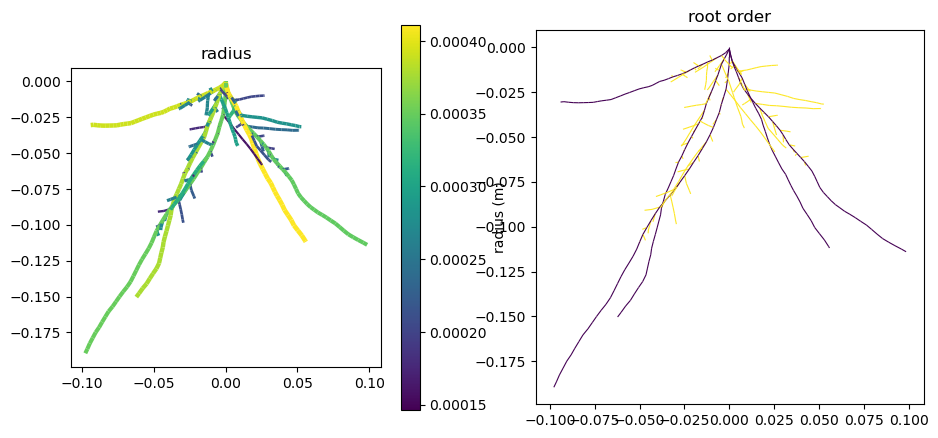

{'length': 1.7616396073471772,
 'struct_mass': 0.0797869904847897,
 'living_struct_mass': 0.08093726060230799,
 'vertices': 786,
 'apices': 386,
 'lateral_apices': 331}

In [5]:
one = Scene(planting(Roots, [{"parameters": WHEAT_SOISSON}]), time_step=3600)
one.simulate(24 * 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
lines = draw_root_system(axes[0], snapshot(one), color_by="radius")
fig.colorbar(lines, ax=axes[0], label="radius (m)")
draw_root_system(axes[1], snapshot(one), color_by="root_order", linewidth_by_radius=False)
axes[0].set_title("radius"); axes[1].set_title("root order")
plt.show()
totals(snapshot(one))

## 4. RootArchitecture: the architecture without carbon

`RootArchitecture` declares no resource: its growth is the potential growth times the **satisfaction coefficient** SC,
the structural mass offered to growth (`struct_mass_input`, a Plant-scale input) over the potential growth's demand,
between 0 and 1 (ArchiSimple; Pagès et al., 2014). Without an offer (its default, infinite), SC = 1. Its parameters are
the architecture's: the carbon ones are RootGrowth's.

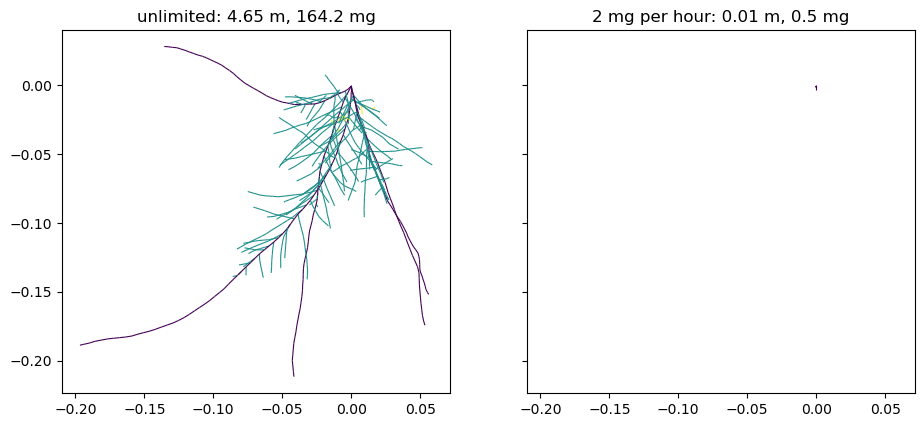

In [6]:
class Architecture:
    initiators = (RootArchitecture,)

    def __init__(self, data_structure, time_step, offer=None):
        self.data_structure, self.offer = data_structure, offer
        self.architecture = RootArchitecture(data_structure=data_structure, time_step=time_step)
        self.components = [self.architecture]

    def run(self):
        if self.offer is not None:                         # g per step and plant
            self.data_structure.set("struct_mass_input", np.full(len(self.data_structure.entity_ids("Plant")),
                                                                 self.offer))
        self.architecture()


architecture_parameters = {k: v for k, v in WHEAT_SOISSON.items() if k in RootArchitecture.__dataclass_fields__}
runs = {}
for label, offer in (("unlimited", None), ("2 mg per hour", 2e-6)):
    # a key the model names in its __init__ (offer) is its own argument; "parameters", its components'
    runs[label] = Scene(planting(Architecture, [{"parameters": architecture_parameters, "offer": offer}]),
                        time_step=3600)
    runs[label].simulate(24 * 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (label, run) in zip(axes, runs.items()):
    draw_root_system(ax, snapshot(run), color_by="root_order", linewidth_by_radius=False)
    t = totals(snapshot(run))
    ax.set_title(f"{label}: {t['length']:.2f} m, {t['struct_mass'] * 1e3:.1f} mg")
plt.show()

## 5. The legacy's behaviours and the reviewed fixes

Some behaviours of the original component were errors (devplan_metafspm.md §6): the pipe model blind to its children,
the growth durations drawn twice, every seminal root drawn the same, ... Each is an option (`legacy_*`, `collar_supply`)
whose default is the fix; `RootGrowth.LEGACY` reproduces the original, bit for bit, for the comparisons.

In [7]:
print(RootGrowth.LEGACY)
legacy = Scene(planting(Roots, [{"parameters": dict(WHEAT_SOISSON, **RootGrowth.LEGACY)}]), time_step=3600)
legacy.simulate(24 * 10)
for label, run in (("legacy", legacy), ("fixed (defaults)", one)):
    t = totals(snapshot(run))
    print(f"{label:18s} {t['length']:.3f} m, {t['struct_mass'] * 1e3:.1f} mg, {t['apices']} apices")

{'legacy_pipe_model': True, 'legacy_primordium_soil_temperature': True, 'legacy_segmentation_masses': True, 'legacy_growth_duration_draws': True, 'legacy_nodule_radius': True, 'legacy_zero_temperature': True, 'legacy_support_development': True, 'legacy_seedling_seeds': True, 'legacy_lateral_growth_extender': True, 'legacy_lateral_diameter_threshold': True, 'legacy_branching_positions': True, 'legacy_dead_living_mass': True, 'life_duration_diameter_exponent': 1.0, 'collar_supply': 'none'}


legacy             1.546 m, 52.2 mg, 318 apices
fixed (defaults)   1.762 m, 79.8 mg, 386 apices


`example/comparison/compare_fixes.py` shows each fix's effect; `compare_root_systems.py` the port against the original,
bit for bit; `profile_growth.py` their cost (the port is about 2.5 times faster, more on larger root systems).

## 6. Resources: a subclass

`RootGrowth.resources` lists the resources limiting growth, each a `Resource`: the declared variables of its
concentration, its supply zone, its costs. The **hooks** are the places where a resource acts: `elongated_length`,
`growth_demand`, `elongation_costs`, `thickening`, `root_hair_costs`, ... each a small array function. A subclass adds
a resource by declaring its variables and overriding the hooks it changes: Root_BRIDGES' carbon-nitrogen growth is
`openalea.rhizodep.growth_CN.RootGrowthCN` (about 250 lines against Root_BRIDGES' 2700; with its LEGACY preset, bit for
bit Root_BRIDGES' results, `test/nitrogen`). An abridged version, the elongation co-limited by amino acids:

```python
@dataclass
class RootGrowthCN(RootGrowth):
    AA: float = input_variable(**doc('mol.g-1', 'Amino acids concentration'), by='model_nitrogen', initialize=0.,
                               scale=SubOrgan, state_variable_type='massic_concentration')
    ...                                                  # the amino acids' supply zone, demand, consumptions
    resources = (HEXOSE, AMINO_ACIDS)

    def elongated_length(self, selected, start_length, radius, time, zone):
        C, AA = zone["C_hexose_root"][selected], zone["AA"][selected]
        share = self._C_share_of_amino_acids(selected)
        limitation = (1 - share) * C / (C + Km_C) + share * AA / (AA + Km_AA)
        return start_length + self._parameter("EL", selected) * 2. * radius * time * limitation
```

## 7. Coupled: the other models' variables follow the structure

When segmentation creates elements, the other components' variables on the same DataStructure are shared between the
new elements and their parents by metafspm (`RootGrowth.repartition = "end_of_call"`), by the living structural mass:
concentrations keep their amounts, extensive variables are split, intensive ones copied. Here another model's
concentration and amount, conserved through 3 days of growth.

In [8]:
from dataclasses import dataclass
from openalea.metafspm.coupling.component import FunctionalComponent, state_variable
from openalea.metafspm.data_structure.configs import ScalesConfig

DOC = dict(unit="", unit_comment="", description="", min_value="", max_value="", value_comment="", references="", DOI="")


@dataclass
class Pools(FunctionalComponent):
    sugar: float = state_variable(**DOC, initialize=1e-3, scale=ScalesConfig.SubOrgan,
                                  state_variable_type="massic_concentration")
    stock: float = state_variable(**DOC, initialize=1., scale=ScalesConfig.SubOrgan, state_variable_type="extensive")


class RootsAndPools(Roots):
    def __init__(self, data_structure, time_step):
        super().__init__(data_structure, time_step)
        self.pools = Pools(data_structure=data_structure)
        self.components.append(self.pools)


coupled = Scene(planting(RootsAndPools, [{"parameters": WHEAT_SOISSON}]), time_step=3600)
ds = coupled.populations[0].data_structure
before = (np.sum(ds.get("sugar") * ds.get("living_struct_mass")), np.sum(ds.get("stock")), ds.n_nodes())
coupled.simulate(72)
after = (np.sum(ds.get("sugar") * ds.get("living_struct_mass")), np.sum(ds.get("stock")), ds.n_nodes())
print(f"elements {before[2]} -> {after[2]}; sugar amount {before[0]:.6g} -> {after[0]:.6g}; stock {before[1]:.6g} -> {after[1]:.6g}")

elements 110 -> 160; sugar amount 5.38783e-08 -> 5.38783e-08; stock 110 -> 110


## 8. A population in one MPG

A stand's plants are grown together: the planting table gives each its position and scenario, and one population
(one model instance, one DataStructure) holds them all, their elements in the same arrays. Each step is one call for
the whole stand, where the original component grows one plant per model, with loops over its MTG. Each plant is the
same as grown alone (`test/test_population.py`: bit for bit the original's, each with its scenario).

The plants of one population differ by their numeric parameters (stored per plant); a switch (a boolean option) is the
population's: plants with another switch make another population, of another model.

The stand grows 10 days: the wheat's laterals emerge a few days after their primordia form (their emergence delay, in thermal
time), so at 5 days they are still primordia, a fraction of a millimetre; at 10 days they make half the length.

In [9]:
import contextlib, io, time
from openalea.metafspm.scene.population import planting_table
from openalea.rhizodep.comparison.legacy_run import legacy_run

n_plants, days = 16, 10
scenarios = [{"parameters": dict(WHEAT_SOISSON, random_choice=1 + k)} for k in range(n_plants)]    # their own draws
stand = planting_table(xrange=0.4, yrange=0.4, sowing_density=n_plants / 0.16, row_spacing=0.1, plant_models=[Roots],
                       plant_scenarios=[scenarios[0]], per_plant_scenarios=scenarios, exact=True, seed=0)
start = time.perf_counter()
population = Scene(stand, time_step=3600)
population.simulate(24 * days)
port_seconds = time.perf_counter() - start
ds = population.populations[0].data_structure
print(f"{len(ds.entity_ids('Plant'))} plants, {ds.n_nodes()} root elements in one MPG: {port_seconds:.1f} s")

start = time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()):                    # the original prints its tables' notes
    for scenario in scenarios:                                     # the original: one plant per model and run
        legacy_run(dict(scenario["parameters"], **RootGrowth.LEGACY), n_steps=24 * days, record=False)
legacy_seconds = time.perf_counter() - start
print(f"the original, plant by plant: {legacy_seconds:.1f} s; the population {legacy_seconds / port_seconds:.1f} times faster")

Launching scene 'population' with 4 rows, 4 plant per rows, which represents 16 plants


16 plants, 10995 root elements in one MPG: 23.7 s


the original, plant by plant: 103.7 s; the population 4.4 times faster


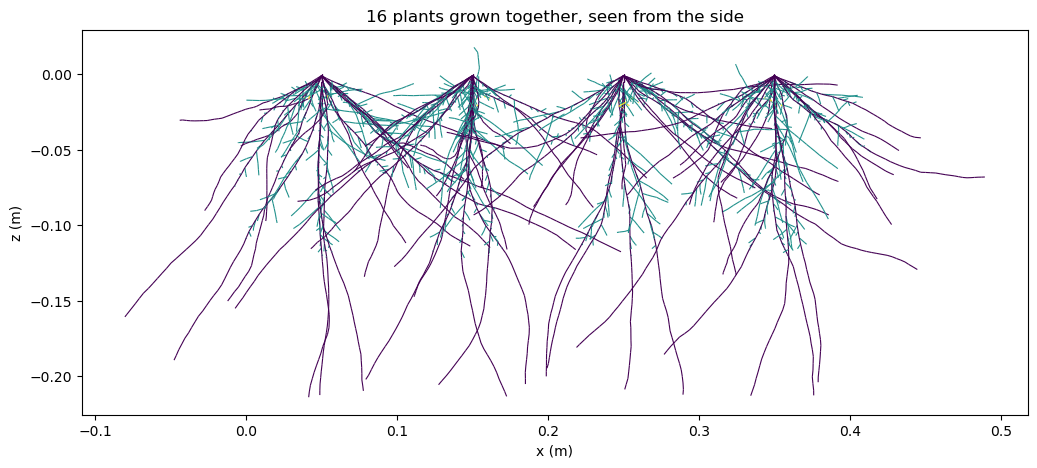

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
for plant in range(n_plants):                                       # each at its position in the row (x)
    draw_root_system(ax, snapshot(population, plant), color_by="root_order", linewidth_by_radius=False,
                     origin=(stand.x[plant], stand.y[plant], 0.), vmin=1, vmax=3)
ax.set_title(f"{n_plants} plants grown together, seen from the side")
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
plt.show()

## 9. Contrasted architectures: parametrization by species

`openalea.rhizodep.parameter_sets` gives a wheat (cv. Soissons, Wheat-BRIDGES' calibration) and ArchiSimple's
calibrations of pea, maize and peach (Pagès et al., 2014): the tip diameters (`D_ini`, `Dmin`), the elongation per
diameter (`EL`), the growth durations (`GDs`), the branching (`IPD`, `RMD`, `CVDD`), the radial growth (`SGC`), the
emission of nodal roots (`n_adventitious_roots`, `ER`). Each is a scenario's parameters. Each set is used in its
calibration's context: the wheat's was fitted with its growth limited by hexose (RootGrowth, here with the hexose given);
ArchiSimple's are potential growth (RootArchitecture, the C-free architecture, its parameters only). The species differ
by their switches too (radial growth), so each is a population of its own: one Scene each, 30 days (maize 20: its nodal roots make it
the largest, 37 000 elements at 20 days). (The drawings have
no gravitropism: the model is topological, its angles only drawn.)

Above, the root orders; below, the radii (the lines' widths and colours, on one logarithmic scale for the four). Pea and peach
(dicotyledons, `SGC` 0.9) thicken their older roots by secondary growth, as the pipe model gives them (each element's
section at least its successor's plus `SGC` times its laterals'): their first-order roots' bases reach several times their tips'
diameter. Wheat and maize (monocotyledons, `SGC` 0) have none: each root keeps its tip's diameter. Note the wheat is
limited by its hexose (here given), the others grow their potential.

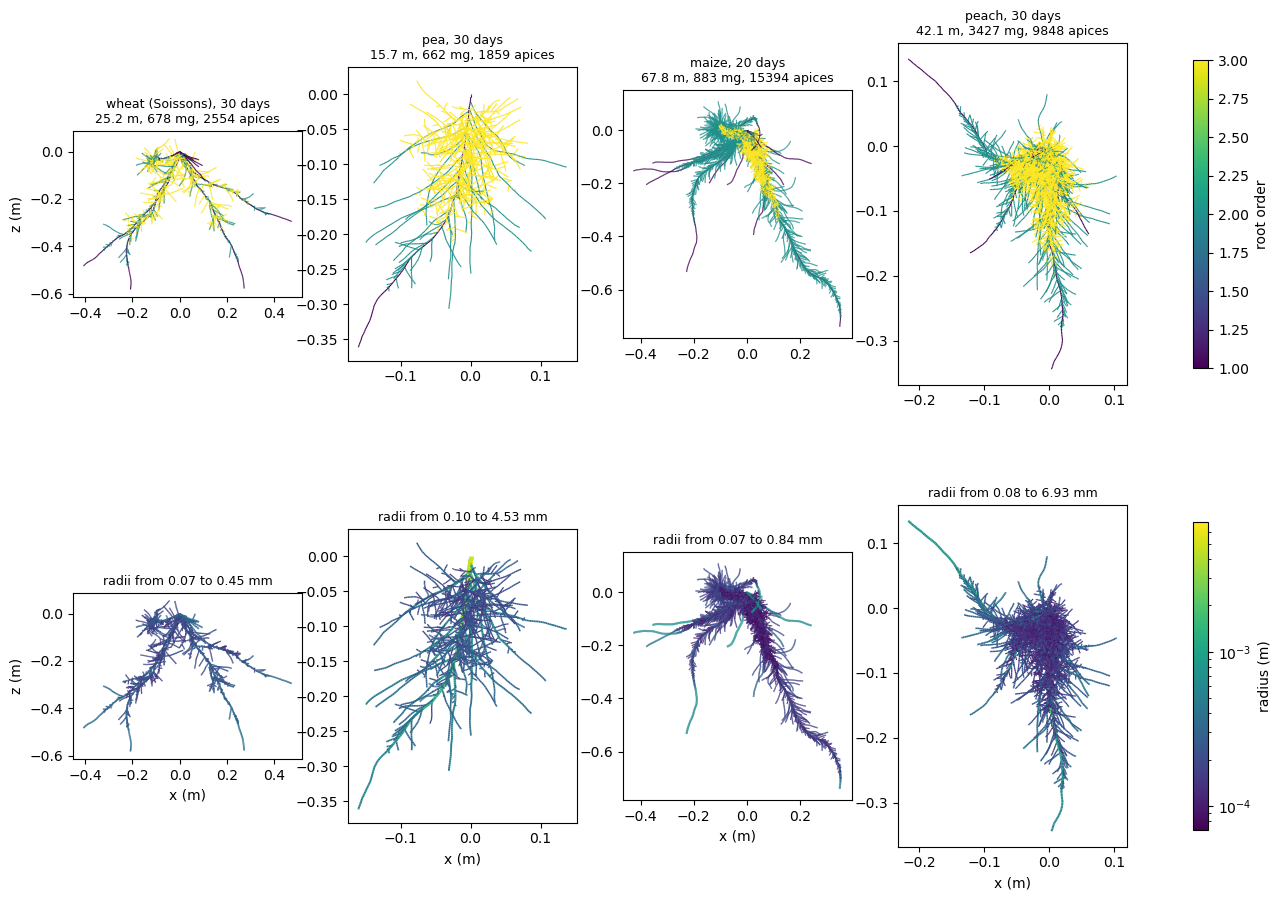

In [11]:
from matplotlib.colors import LogNorm
from openalea.rhizodep.parameter_sets import SPECIES

days = {"maize": 20}                                               # 30 days for the others
records = {}
for species, parameters in SPECIES.items():
    if species.startswith("wheat"):                                # RootGrowth, its hexose given
        stand = Scene(planting(Roots, [{"parameters": parameters}]), time_step=3600)
    else:                                                          # RootArchitecture, potential growth
        own = {name: value for name, value in parameters.items() if name in RootArchitecture.__dataclass_fields__}
        stand = Scene(planting(Architecture, [{"parameters": own}]), time_step=3600)
    stand.simulate(24 * days.get(species, 30))
    records[species] = snapshot(stand)

radii_of = {species: np.array([record.props["radius"][vertex] for vertex in record.vertices]) for species, record in records.items()}
smallest = min(radii[radii > 0].min() for radii in radii_of.values())
largest = max(radii.max() for radii in radii_of.values())
fig, axes = plt.subplots(2, len(SPECIES), figsize=(17, 11))
for column, (species, record) in enumerate(records.items()):
    orders = draw_root_system(axes[0, column], record, color_by="root_order", linewidth_by_radius=False, vmin=1, vmax=3)
    radii = draw_root_system(axes[1, column], record, color_by="radius")
    radii.set_norm(LogNorm(smallest, largest))                      # one scale for the four, logarithmic
    radii.set_linewidths(0.3 + 4. * np.sqrt(radii.get_array() / largest))
    t = totals(record)
    axes[0, column].set_title(f"{species}, {days.get(species, 30)} days\n{t['length']:.1f} m, {t['struct_mass'] * 1e3:.0f} mg, {t['apices']} apices",
                              fontsize=9)
    axes[1, column].set_title(f"radii from {radii_of[species][radii_of[species] > 0].min() * 1e3:.2f} "
                              f"to {radii_of[species].max() * 1e3:.2f} mm", fontsize=9)
    axes[1, column].set_xlabel("x (m)")
for row in axes:
    row[0].set_ylabel("z (m)")
fig.colorbar(orders, ax=axes[0].tolist(), label="root order", shrink=0.8)
fig.colorbar(radii, ax=axes[1].tolist(), label="radius (m)", shrink=0.8)
plt.show()